# Required Experience from IT Vacancies — Final

Machine Learning Algorithms, Astana IT University · Zholdubayev Diyar and Galymzhan Turemuratov

**Question.** Can we predict the experience an employer requires on hh.ru (no experience, 1–3, 3–6 or 6+ years) from a real IT vacancy? Does the **vacancy text** add value beyond the structured fields (salary, key skills, schedule, employment type, city)?

This notebook runs on the saved sample, the saved split and the saved models in this repository. It calls the same functions as the scripts in `src/`, recomputes every test metric from the saved models, and checks them against `results/tables/final_comparison.csv`.

To retrain everything from scratch inside the notebook, set `RUN_TRAINING = True` below. This takes about 20 minutes on a laptop CPU.

The full write-up is in `REPORT.md`.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import LABELS, LABEL_NAMES, MODELS, SEED
from src.data import load_dataset
from src.features import add_embeddings, build_frame, mask_text, metrics
from src.modeling import embeddings_for, load_registry

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 160)
RUN_TRAINING = False
print('Project root:', ROOT.name, '| seed:', SEED)

Project root: Final-ML | seed: 42


## 1. Data

- **Source:** *IT vacancies from hh.ru, 2006–2020* (Bersenev et al., IEEE DataPort, doi:10.21227/6naz-wb22, CC BY 4.0), 2020 file.
- **Sample and split:** `src/prepare_data.py` filtered the file, removed duplicates and drew a fixed, stratified 20,000-vacancy sample. It saved an 80/20 split by vacancy ID, grouped by employer, so no employer appears in both train and test.
- **Integrity check:** `load_dataset()` first checks the SHA-256 hashes in `data/processed/manifest.json`.

In [2]:
manifest = json.loads(Path('data/processed/manifest.json').read_text())
frame, train, test = load_dataset()
print(f"Source: {manifest['source']}")
print(f"After filters: {manifest['rows_after_filters']:,} | after de-duplication: {manifest['rows_after_dedup']:,}")
print(f"Sample: {len(frame):,} | train: {len(train):,} | test: {len(test):,}")
print(f"Employers in train: {train.employer_id.nunique():,} | in test: {test.employer_id.nunique():,} | shared: {len(set(train.employer_id) & set(test.employer_id))}")

classes = pd.DataFrame({
    'train': train.experience_id.value_counts(),
    'test': test.experience_id.value_counts(),
}).loc[LABELS]
classes['test share'] = (classes['test'] / classes['test'].sum()).round(3)
classes.index = [LABEL_NAMES[c] for c in classes.index]
classes

Source: IEEE DataPort, IT vacancies from hh.ru 2006-2020, doi:10.21227/6naz-wb22, CC BY 4.0
After filters: 587,493 | after de-duplication: 390,967
Sample: 20,000 | train: 16,001 | test: 3,999
Employers in train: 8,256 | in test: 2,060 | shared: 0


,train,test,test share
No experience,2702,675,0.169
1-3 years,8362,2090,0.523
3-6 years,4489,1122,0.281
More than 6 years,448,112,0.028


In [3]:
missing = pd.Series({
    'salary missing': test.salary_missing.mean(),
    'salary in another currency': test.salary_other_currency.mean(),
    'no key skills': (test.n_skills == 0).mean(),
}).round(3).rename('share of test vacancies')
missing.to_frame()

,share of test vacancies
salary missing,0.495
salary in another currency,0.049
no key skills,0.218


## 2. Leakage control: masking the description

Many descriptions state the answer directly, for example «опыт работы от 3 лет» or «без опыта». Before any text model sees a description, `mask_text` removes the vacancy title, explicit experience phrases and seniority words.

The example below is made up to illustrate the forms the masking handles. It is not a real vacancy.

In [4]:
example = ('Ищем Senior Java-разработчика. Требования: опыт работы от 3-х лет, Spring, PostgreSQL. '
           'Опыт с Kafka приветствуется. Подарки на новый год.')
print('Before:', example)
print('After: ', mask_text(example))

Before: Ищем Senior Java-разработчика. Требования: опыт работы от 3-х лет, Spring, PostgreSQL. Опыт с Kafka приветствуется. Подарки на новый год.
After:  Ищем Java-разработчика. Требования: опыт работы , Spring, PostgreSQL. . Подарки на новый год.


The masking also has a cost. «Опыт с Kafka приветствуется» is removed as a whole, so the skill name Kafka is lost from the text. It still reaches the structured model through `key_skills` when the employer lists it there. In real use the vacancy title is removed too, as an exact, case-insensitive match.

How often each masking pattern fired on the training descriptions (`results/tables/text_leak_audit.csv`). The first pattern, numeric experience phrases, fired in about 44% of them. This is why masking is essential.

In [5]:
audit = pd.read_csv('results/tables/text_leak_audit.csv')
audit.assign(pattern=audit.pattern.str[:70])[['pattern', 'train_rows_matched', 'share']].round(3)

,pattern,train_rows_matched,share
0,(?:\b(?:не\s+)?(?:менее|более|больше|меньше|от|свыше|минимум|до|at\s+l,7067,0.442
1,(?:\b(?:не\s+)?(?:менее|более|больше|меньше|от|свыше|минимум|до|at\s+l,1692,0.106
2,\b(?:не\s+)?(?:менее|более|больше|от|свыше|минимум)\s+(?:года|год)\b,262,0.016
3,\b(?:без опыта(?: работы)?|нет опыта|no experience|without experience|,321,0.020
4,"\bопыт\w*(?:\s+[\w/-]+){0,5}?\s+(?:не\s+)?(?:обязател\w*|требуется|нуж",782,0.049
5,\b(?:но\s+)?не\s+(?:обязател\w*|требуется)\b,294,0.018
6,\b(?:junior|middle|senior|team\s*lead|lead|intern|internship|trainee|h,2799,0.175


**Check after masking:** the strongest words of the TF-IDF model per class, fitted on training data only. If experience wording such as «3х лет» or «не менее» had survived, it would show up here. The first version of the masking failed this check, and the patterns were fixed (see `REPORT.md`, section 5.2).

In [6]:
terms = pd.read_csv('results/tables/tfidf_top_terms.csv')
(terms[terms['rank'] <= 15].groupby('class')['term'].apply(', '.join)
 .rename(index=LABEL_NAMES).to_frame('top 15 terms'))

,top 15 terms
class,
1-3 years,"опыт, опыт работы, требования опыт, работы, график работы, образование опыт, выполнение, график, профессиональный, с..."
3-6 years,"опыт, опыт работы, разработка, должности, умение, участвовать, стаж работы, планирования, стаж, аналогичной должност..."
More than 6 years,"опыт управления, опыт, группы, архитектуры, объектов, опыт руководства, ит, управление, аналоговых, azure, system, р..."
No experience,"обучение, желание, пк, требования знание, базовые, развиваться, научим, обучаться, обязанности, карьеру, обучаемость..."


## 3. Training (optional)

The models were trained with `python -m src.train_structured` and `python -m src.train_text`. Every model and hyperparameter is chosen by 5-fold cross-validation on the training set only, grouped by employer and scored with macro F1. Set `RUN_TRAINING = True` to rerun it here.

In [7]:
if RUN_TRAINING:
    from src import train_structured, train_text, evaluate
    train_structured.main()
    train_text.main([])
    evaluate.main()
else:
    print('Using saved models from models/ (set RUN_TRAINING = True to retrain).')

Using saved models from models/ (set RUN_TRAINING = True to retrain).


## 4. Results on the held-out test set

Each saved model is loaded and predicts the same 3,999 test vacancies. The table is sorted by training cross-validation score, which is how models were chosen. Test scores are only reported.

In [8]:
registry = load_registry()
models = registry['models']
test_e = add_embeddings(frame, embeddings_for(frame)).loc[test.index]

preds, rows = test[['id', 'name', 'experience_id', 'salary_missing', 'n_skills', 'desc_words']].copy(), []
for name, info in models.items():
    model = joblib.load(MODELS / info['file'])
    preds[name] = model.predict(test_e if info['needs_embeddings'] else test)
    rows.append({'model': name, 'input': info['kind'], 'cv_macro_f1': info['cv_mean'], 'cv_std': info['cv_std'],
                 **{f'test_{k}': v for k, v in metrics(test.experience_id, preds[name]).items()}})
comparison = pd.DataFrame(rows).sort_values('cv_macro_f1', ascending=False).reset_index(drop=True)

saved = pd.read_csv('results/tables/final_comparison.csv').set_index('model')
check = comparison.set_index('model')[['test_macro_f1', 'test_accuracy']]
assert np.allclose(check.values, saved.loc[check.index, ['test_macro_f1', 'test_accuracy']].values, atol=1e-9)
print('Recomputed test metrics match results/tables/final_comparison.csv')
comparison.round(3)

Recomputed test metrics match results/tables/final_comparison.csv


,model,input,cv_macro_f1,cv_std,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall
0,Structured + TF-IDF + LR,structured+tfidf,0.435,0.013,0.532,0.452,0.438,0.490
1,TF-IDF + LR,tfidf,0.426,0.019,0.514,0.426,0.415,0.454
2,Structured + rubert-tiny2 + Boosting,structured+embed,0.406,0.018,0.490,0.413,0.402,0.450
3,Random Forest,structured,0.376,0.023,0.488,0.397,0.391,0.411
4,Boosting,structured,0.358,0.020,0.426,0.364,0.366,0.416
5,rubert-tiny2 + LR,embed,0.348,0.016,0.559,0.369,0.449,0.358
6,Logistic Regression,structured,0.326,0.009,0.551,0.336,0.409,0.333
7,Dummy,structured,0.172,0.000,0.523,0.172,0.131,0.250


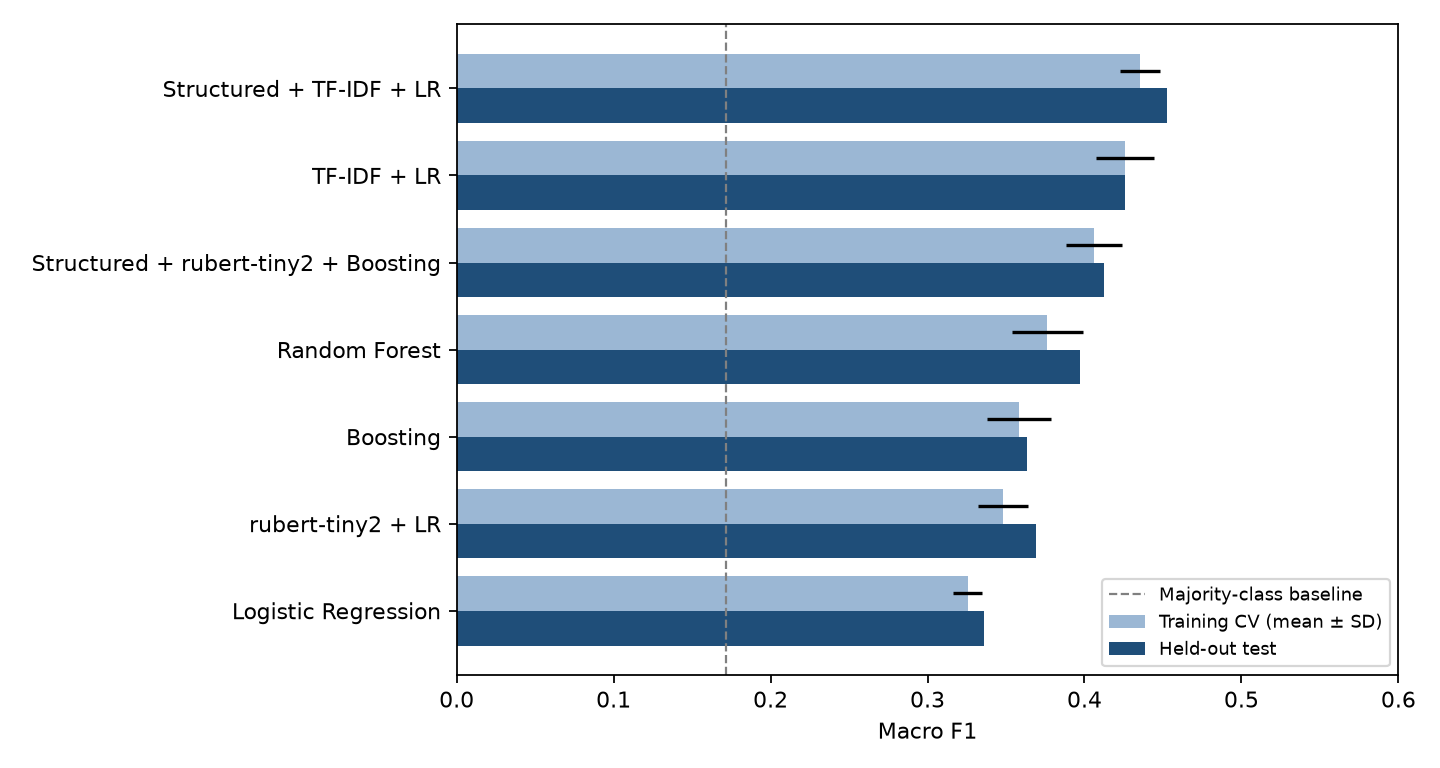

In [9]:
display(Image('results/figures/model_comparison.png', width=900))

### Does the text add value? Paired comparison on the same test vacancies

We compare the best structured model (Random Forest) with the best text-containing model (structured fields + TF-IDF), both chosen by CV. The exact McNemar test looks only at vacancies where exactly one of the two models is right.

In [10]:
from scipy.stats import binomtest

best_struct, best_text = 'Random Forest', 'Structured + TF-IDF + LR'
y = preds.experience_id
text_only_right = int(((preds[best_text] == y) & (preds[best_struct] != y)).sum())
struct_only_right = int(((preds[best_struct] == y) & (preds[best_text] != y)).sum())
p = binomtest(min(text_only_right, struct_only_right), text_only_right + struct_only_right, 0.5).pvalue
print(f'Only {best_text} right: {text_only_right}')
print(f'Only {best_struct} right: {struct_only_right}')
print(f'Exact McNemar p-value: {p:.2e}')

Only Structured + TF-IDF + LR right: 808
Only Random Forest right: 632
Exact McNemar p-value: 3.89e-06


In [11]:
from sklearn.metrics import classification_report

per_class = pd.DataFrame({
    name: {LABEL_NAMES[c]: classification_report(y, preds[name], labels=LABELS, output_dict=True, zero_division=0)[c]['f1-score']
           for c in LABELS}
    for name in [best_struct, best_text, 'TF-IDF + LR', 'rubert-tiny2 + LR']
}).round(3)
per_class.index.name = 'test F1 by class'
per_class

,Random Forest,Structured + TF-IDF + LR,TF-IDF + LR,rubert-tiny2 + LR
test F1 by class,,,,
No experience,0.467,0.534,0.524,0.402
1-3 years,0.551,0.582,0.565,0.676
3-6 years,0.445,0.502,0.471,0.366
More than 6 years,0.125,0.192,0.142,0.032


## 5. The Endterm hypothesis: where does the text help?

The Endterm found that vacancies **without salary** had about three times more errors. Here we split the test set by whether salary or skills are missing.

In [12]:
subgroups = pd.read_csv('results/tables/subgroups.csv')
subgroups.pivot(index='group', columns='model', values='macro_f1').join(
    subgroups.drop_duplicates('group').set_index('group')['n']).round(3)

,Random Forest,Structured + TF-IDF + LR,n
group,,,
long description,0.328,0.417,1201
no key skills,0.375,0.456,870
salary missing,0.309,0.424,1979
salary present,0.447,0.447,2020
short description,0.383,0.448,1506


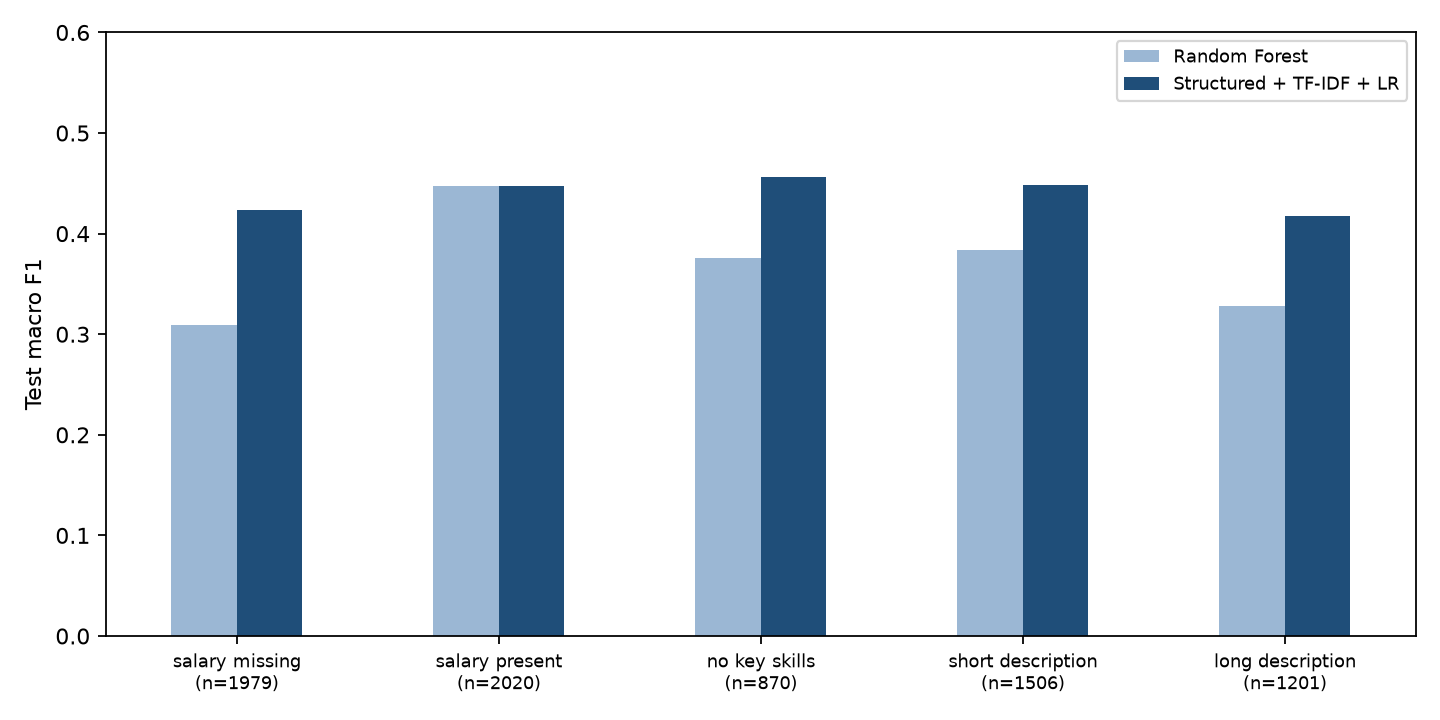

In [13]:
display(Image('results/figures/subgroups.png', width=900))

**Reading.** Without salary, the structured model drops to about 0.31 macro F1, and adding the text brings it to about 0.42. With salary present, the two are equal. The text fills the gap left by missing structured fields, so the hypothesis is supported.

## 6. Pretrained encoder vs our own TF-IDF model

`rubert-tiny2 + LR` uses frozen embeddings from a pretrained Russian BERT. It has the highest accuracy but low macro F1, because it mostly predicts the majority class:

In [14]:
recall = pd.DataFrame({
    name: {LABEL_NAMES[c]: classification_report(y, preds[name], labels=LABELS, output_dict=True, zero_division=0)[c]['recall']
           for c in LABELS}
    for name in ['TF-IDF + LR', 'rubert-tiny2 + LR']
}).round(3)
recall.index.name = 'test recall by class'
recall

,TF-IDF + LR,rubert-tiny2 + LR
test recall by class,,
No experience,0.640,0.307
1-3 years,0.501,0.808
3-6 years,0.496,0.301
More than 6 years,0.179,0.018


## 7. Error analysis with real test vacancies

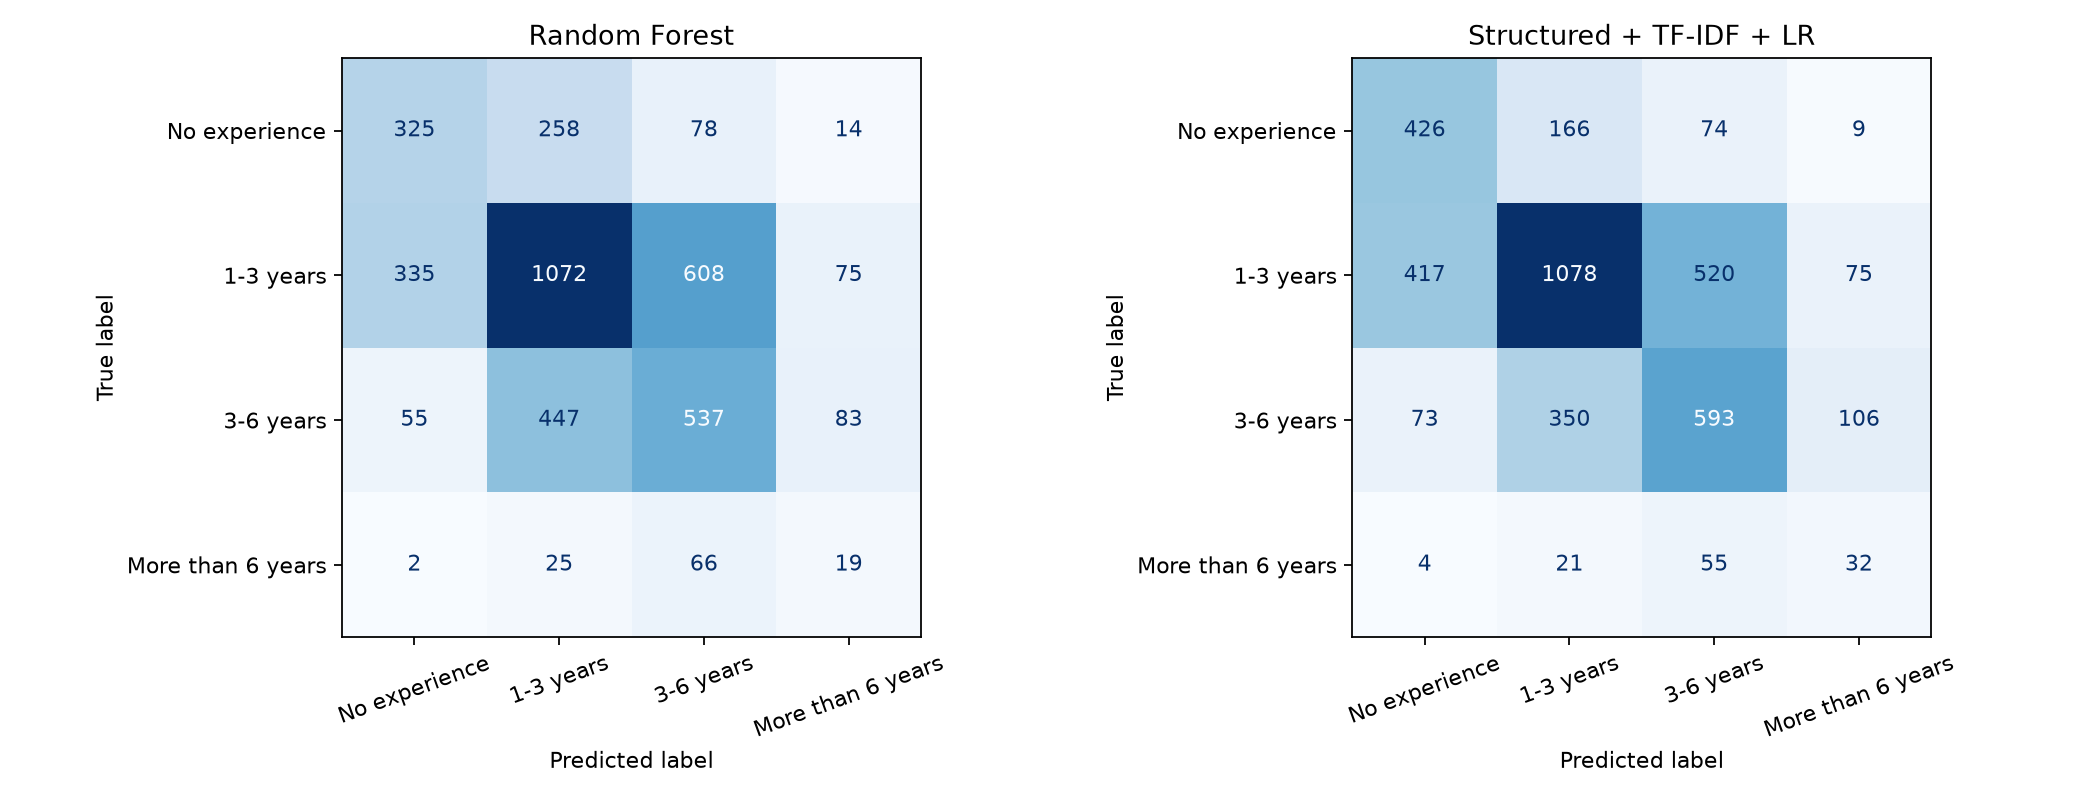

Random Forest: 2046 errors, 88% of them one level off
Structured + TF-IDF + LR: 1870 errors, 86% of them one level off


In [15]:
display(Image('results/figures/confusion_matrices.png', width=1000))

order = {c: i for i, c in enumerate(LABELS)}
for name in [best_struct, best_text]:
    true_level = y.map(order)
    predicted_level = preds[name].map(order)
    wrong = predicted_level != true_level
    adjacent = ((predicted_level - true_level).abs() == 1)[wrong].mean()
    print(f'{name}: {wrong.sum()} errors, {adjacent:.0%} of them one level off')

In [16]:
ids = ['38034824', '35544251', '40352066', '38477240', '35180911', '38715353']
examples = preds.set_index('id').loc[ids, ['name', 'experience_id', best_struct, best_text, 'salary_missing']]
examples = examples.rename(columns={'name': 'title (not used by models)', 'experience_id': 'true'})
examples['masked text (start)'] = test.set_index('id').loc[ids, 'text'].str[:160]
examples

,title (not used by models),true,Random Forest,Structured + TF-IDF + LR,salary_missing,masked text (start)
id,,,,,,
38034824,Администратор компьютерного клуба,noExperience,between1And3,noExperience,1,"COLIZEUM Cyber Sport Arena- это самая активная быстрорастущая сеть кибер арен в России с топовыми оборудованием, сти..."
35544251,Аккаунт-Менеджер/менеджер по работе с клиентами.,noExperience,between3And6,noExperience,1,"Требуется Аккаунт-менеджер / менеджер проектов по контекстной рекламе, таргетированной рекламе, seo, разработке и те..."
40352066,Начальник центра технической эксплуатации телекоммуникаций (Связь),between3And6,between1And3,between3And6,1,Обязанности: Обеспечение бесперебойной работы сети связи в зоне ответственности центра Выполнение количественных и к...
38477240,Начальник отдела сопровождения сервисов и систем BI,moreThan6,between1And3,between1And3,1,"Чем предстоит заниматься? Сопровождение BI-систем и хранилищ данных, решение инцидентов и проблем, выработка и внедр..."
35180911,Веб-разработчик .NET,moreThan6,between3And6,between3And6,1,Мы ищем разработчика для работы над новыми и уже существующими веб приложениями. Основная часть работы будет посвяще...
38715353,Специалист ИТ,moreThan6,between1And3,between1And3,0,"Обязанности: обслуживание компьютеров, ноутбуков Windows XP/7/8/10; настройка новых рабочих мест для сотрудников; на..."


## 8. Prediction on a new vacancy

The app (`streamlit run app/app.py`) follows the same path for new input: `build_frame` → `mask_text` → the saved pipeline. The example below is a made-up vacancy, not one from the dataset.

In [17]:
app_model_name = registry['app_model']
app_model = joblib.load(MODELS / models[app_model_name]['file'])
new = pd.DataFrame([{
    'id': 'new', 'name': 'Аналитик данных', 'key_skills': 'SQL, Excel',
    'description': 'Ищем начинающего аналитика. Научим работать с отчётностью. Знание SQL и Excel.',
    'salary_from': 50000, 'salary_to': 70000, 'salary_currency': 'RUR', 'salary_gross': None,
    'schedule_id': 'fullDay', 'employment_id': 'full', 'area_name': 'Москва',
}])
new_frame = build_frame(new)
proba = pd.Series(app_model.predict_proba(new_frame)[0], index=[LABEL_NAMES[c] for c in app_model.classes_]).round(3)
print('Model:', app_model_name)
print('Masked text:', new_frame.text.iloc[0])
proba.sort_values(ascending=False).to_frame('probability')

Model: Structured + TF-IDF + LR
Masked text: Ищем начинающего аналитика. Научим работать с отчётностью. Знание SQL и Excel.


,probability
No experience,0.766
1-3 years,0.163
3-6 years,0.065
More than 6 years,0.006


## 9. Conclusion

- The vacancy text **significantly improves** prediction of the employer's required experience. Test macro F1 rises from 0.397 for the best structured model to 0.452 for structured + TF-IDF (exact McNemar p ≈ 4·10⁻⁶).
- The gain is concentrated where **salary or key skills are missing**, which confirms the Endterm hypothesis.
- Our own TF-IDF model **beat** the frozen pretrained encoder (rubert-tiny2).
- The main limits:
  - neighbouring levels are fuzzy in the labels themselves (most errors are one level off);
  - the 6+ years class is rare;
  - the data is one year (2020) from one site;
  - the masking is pattern-based.

See `REPORT.md` for the full discussion, existing solutions and contributions.